# 04 – HMM sur les rendements réels du Bitcoin + prédiction du prochain régime
Données : **BTCUSDT**, bougies de **8 h** (1 jour = 3 lignes), préparées par le notebook `01_donnees`. Observations : rendement log et volatilité. Étapes : chargement des fichiers train/test → choix de N (AIC/BIC) → interprétation → **prédiction sans look-ahead bias**.

**Exécuter d'abord `01_donnees.ipynb`** : ce notebook relit ses fichiers (même features, même découpage, même transformation gaussienne).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from hmmlearn.hmm import GaussianHMM
from scipy.stats import multivariate_normal
np.set_printoptions(precision=4, suppress=True)

DOSSIER  = "../data/btcusdt"   # fichiers produits par 01_donnees.ipynb
PAR_JOUR = 3                   # bougies de 8 h : 1 jour = 3 lignes

> **Interprétation :**
>
> On charge les bibliothèques. On ne recalcule rien ici : on relit les fichiers préparés par le notebook 01.

## 1. Chargement des données préparées (notebook 01)
`X_train` / `X_test` ont déjà été **transformés pour suivre une loi normale N(0, 1)** (transformation par quantiles, ajustée sur le train seulement, voir notebook 01). C'est ce qu'il faut pour un HMM **gaussien**. `scaler.inverse_transform` permet de revenir aux valeurs d'origine (rendement et volatilité en %). Le fichier de features complet sert à retrouver le prix (`Close`) et le rendement brut pour l'évaluation.

In [2]:
X_train_df = pd.read_csv(f"{DOSSIER}_X_train.csv", index_col=0, parse_dates=True)
X_test_df  = pd.read_csv(f"{DOSSIER}_X_test.csv",  index_col=0, parse_dates=True)
feat       = pd.read_csv(f"{DOSSIER}_features.csv", index_col=0, parse_dates=True)
scaler     = joblib.load(f"{DOSSIER}_scaler.joblib")

colonnes = list(X_train_df.columns)
assert colonnes == list(scaler.feature_names_in_) and {"rendement", "volatilite"} <= set(colonnes)
X_train, X_test = X_train_df.values, X_test_df.values
test = feat.loc[X_test_df.index]                     # prix et features brutes de la période de test
print(f"Features : {colonnes}")
print(f"train : {X_train_df.index[0]} -> {X_train_df.index[-1]} ({len(X_train)} lignes = {len(X_train) // PAR_JOUR} jours)")
print(f"test  : {X_test_df.index[0]} -> {X_test_df.index[-1]} ({len(X_test)} lignes = {len(X_test) // PAR_JOUR} jours)")

Features : ['rendement', 'volatilite']
train : 2017-09-06 00:00:00 -> 2024-02-01 16:00:00 (7014 lignes = 2338 jours)
test  : 2024-02-02 00:00:00 -> 2026-10-31 16:00:00 (3009 lignes = 1003 jours)


C:\Users\User\Desktop\projet_hmm_crypto\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator QuantileTransformer from version 1.5.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


> **Interprétation :**
>
> On retrouve exactement les mêmes données que dans le notebook 01 : **2 variables** (rendement, volatilité), **2 338 jours de train** et **1 003 jours de test**. Les valeurs sont maintenant **gaussiennes** (loi N(0, 1) sur le train) : l'hypothèse de base du `GaussianHMM` est respectée.

## 2. Choix du nombre d'états N (AIC / BIC)
Nombre de paramètres d'un HMM gaussien à covariance pleine, avec `d` variables : `k = (N−1) + N(N−1) + N·d + N·d(d+1)/2`.

,logL,k,AIC,BIC
N,,,,
2,-16308.7,13,32643.5,32732.6
3,-13789.0,23,27624.0,27781.7
4,-11886.7,35,23843.4,24083.4
5,-10474.2,49,21046.4,21382.3


N optimal selon BIC : 5 | selon AIC : 5


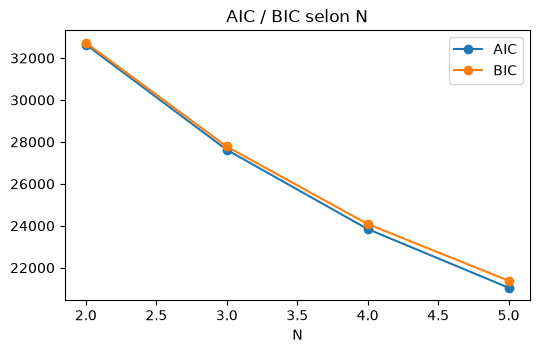

In [3]:
def meilleur_modele(X, N, n_init=8):
    best, best_ll = None, -np.inf
    for seed in range(n_init):                      # plusieurs initialisations (optimum local)
        m = GaussianHMM(n_components=N, covariance_type="full", n_iter=300, tol=1e-4, random_state=seed)
        try:
            m.fit(X); ll = m.score(X)
        except Exception:
            continue
        if ll > best_ll: best, best_ll = m, ll
    return best, best_ll

d, n = X_train.shape[1], len(X_train)
lignes, modeles = [], {}
for N in range(2, 6):
    m, ll = meilleur_modele(X_train, N)
    k = (N-1) + N*(N-1) + N*d + N*d*(d+1)//2
    lignes.append({"N": N, "logL": ll, "k": k, "AIC": 2*k - 2*ll, "BIC": k*np.log(n) - 2*ll})
    modeles[N] = m
tab = pd.DataFrame(lignes).set_index("N"); display(tab.round(1))
N_BIC = int(tab["BIC"].idxmin()); N_AIC = int(tab["AIC"].idxmin())
print("N optimal selon BIC :", N_BIC, "| selon AIC :", N_AIC)
tab[["AIC", "BIC"]].plot(marker="o", figsize=(6, 3.5), title="AIC / BIC selon N"); plt.show()

> **Interprétation :**
>
> Plus l'AIC et le BIC sont **bas**, meilleur est le modèle. Ils baissent encore de N = 2 à N = 5 : le critère préfère **5 états**.
> Les queues épaisses ont pourtant disparu avec la transformation gaussienne. Si le critère ajoute encore des états, c'est que la volatilité varie **de façon continue et très persistante** : le modèle découpe ses niveaux en paliers de plus en plus fins (calme, moyen, agité, très agité…), et chaque palier supplémentaire améliore la vraisemblance sur 7 014 bougies.
> Le sujet demande 3 régimes (haussier, baissier, panique) : on garde **N = 3** pour l'interprétation, et on discutera ce choix dans le rapport.

## 3. Modèle retenu et interprétation économique
Le sujet demande 3 états (haussier, baissier, panique). On prend `N = 3` pour l'interprétation et on compare avec le choix du BIC dans le rapport. Les états sont **triés par rendement moyen** pour que « 0 = le plus baissier ».

In [4]:
N = 3
model = modeles[N]
i_rend, i_vol = colonnes.index("rendement"), colonnes.index("volatilite")
ordre = np.argsort(model.means_[:, i_rend])          # tri par rendement moyen croissant
mu_brut = scaler.inverse_transform(model.means_)[ordre]
A = model.transmat_[np.ix_(ordre, ordre)]
pi0 = model.startprob_[ordre]
covs = model.covars_[ordre]; means = model.means_[ordre]

resume = pd.DataFrame(mu_brut, columns=[f"{c} moyen(ne)" for c in colonnes])
resume["durée moyenne (bougies)"] = 1 / (1 - np.diag(A))
resume["durée moyenne (jours)"]  = resume["durée moyenne (bougies)"] / PAR_JOUR
resume.index = ["État 0 (rendement le plus bas)", "État 1", "État 2 (rendement le plus haut)"]
display(resume.round(5))
print("Matrice de transition (états triés) :\n", A.round(3))

,rendement moyen(ne),volatilite moyen(ne),durée moyenne (bougies),durée moyenne (jours)
État 0 (rendement le plus bas),0.00011,0.01115,121.08709,40.36236
État 1,0.00016,0.01851,52.78449,17.59483
État 2 (rendement le plus haut),0.00066,0.02957,85.00094,28.33365


Matrice de transition (états triés) :
 [[0.992 0.008 0.   ]
 [0.009 0.981 0.01 ]
 [0.    0.012 0.988]]


> **Interprétation :**
>
> Les 3 états trouvés, triés du rendement le plus bas au plus haut (valeurs remises à l'échelle d'origine avec `inverse_transform`) :
> - **État 0 :** rendement quasi nul (0,011 % par bougie) et **volatilité faible (1,1 %)**. C'est un marché **calme**, et c'est le plus persistant : **40 jours** en moyenne.
> - **État 1 :** rendement légèrement positif et **volatilité moyenne (1,9 %)**. C'est le régime le plus court (**18 jours**) : un régime de **transition**.
> - **État 2 :** **meilleur rendement (0,066 % par bougie)** et **volatilité forte (3,0 %)**, pendant 28 jours en moyenne. Dans le train (2017-2024), les périodes très agitées sont aussi celles des grandes hausses (bulles de 2017 et 2021), d'où un rendement moyen élevé.
>
> **Matrice de transition :** la diagonale vaut 0,98 à 0,99, donc les régimes durent longtemps. Les transitions 0 → 2 et 2 → 0 valent **0** : on ne passe jamais directement du calme à l'agitation. Le marché **monte et descend l'échelle de la volatilité** en passant toujours par l'état intermédiaire.

In [5]:
# Étiquetage automatique : volatilité la plus forte = Panique ; parmi les 2 autres, rendement le plus haut = Haussier ; reste = Baissier
vol = mu_brut[:, i_vol]
etiquettes = {}
etiquettes[int(np.argmax(vol))] = "Panique"
reste = [i for i in range(3) if i not in etiquettes]
etiquettes[reste[int(np.argmax(mu_brut[reste, i_rend]))]] = "Haussier"
etiquettes[[i for i in range(3) if i not in etiquettes][0]] = "Baissier"
NOMS = [etiquettes[i] for i in range(3)]
print("Étiquettes :", dict(enumerate(NOMS)), "(à vérifier à la main dans le rapport)")

Étiquettes : {0: 'Baissier', 1: 'Haussier', 2: 'Panique'} (à vérifier à la main dans le rapport)


> **Interprétation :**
>
> Le programme donne automatiquement un nom à chaque état : le plus volatil = **Panique**, celui qui rapporte le plus parmi les deux autres = **Haussier**, le dernier = **Baissier**.
> **Attention aux noms :**
> - l'état « Baissier » a un rendement **positif** (faible) et la volatilité la plus basse : il vaudrait mieux l'appeler **« Calme »** ;
> - l'état « Panique » a le rendement moyen **le plus élevé** : c'est un régime **très agité**, qui contient à la fois les krachs et les envolées.
>
> Le HMM sépare donc surtout les marchés selon leur **niveau de volatilité**, pas selon leur direction.

### Vérification : les observations sont-elles gaussiennes **dans chaque état** ?
Le `GaussianHMM` suppose que, **une fois l'état connu**, les observations suivent une loi normale. On attribue chaque bougie du train à son état le plus probable (Viterbi), puis on mesure l'asymétrie, la kurtosis en excès (0 pour une loi normale) et la part des valeurs au-delà de 3σ (0,27 % pour une loi normale), état par état.

In [6]:
from scipy import stats
etats_train = ordre.argsort()[model.predict(X_train)]          # états du train, dans l'ordre trié
lignes = []
for i in range(N):
    for j, c in enumerate(colonnes):
        x = X_train[etats_train == i, j]
        z = (x - x.mean()) / x.std()
        lignes.append({"état": f"{i} ({NOMS[i]})", "variable": c, "n": len(x), "asymétrie": stats.skew(x),
                       "kurtosis en excès": stats.kurtosis(x), "% au-delà de 3σ": 100 * np.mean(np.abs(z) > 3)})
display(pd.DataFrame(lignes).set_index(["état", "variable"]).round(2))

n  asymétrie  kurtosis en excès  % au-delà de 3σ
état         variable                                                       
0 (Baissier) rendement   2547       0.04               0.31             0.31
             volatilite  2547      -1.20               2.16             1.06
1 (Haussier) rendement   2395      -0.02              -0.41             0.13
             volatilite  2395      -0.00              -1.04             0.00
2 (Panique)  rendement   2072      -0.05              -0.51             0.10
             volatilite  2072       1.26               2.53             1.16

> **Interprétation :**
>
> **Le rendement est bien gaussien dans chaque état** : asymétrie proche de 0 (entre −0,05 et 0,04), kurtosis en excès entre −0,5 et 0,3, et 0,1 à 0,3 % de valeurs au-delà de 3σ (0,27 % pour une loi normale). Pour comparaison, **avant la transformation**, la kurtosis du rendement dans les états valait entre 2 et 5 : l'hypothèse du HMM gaussien est maintenant **beaucoup mieux respectée**.
> **La volatilité** est gaussienne dans l'état intermédiaire, mais un peu asymétrique dans les deux états extrêmes (asymétrie −1,2 dans l'état calme, +1,3 dans l'état agité). C'est logique : ces états sont « coupés » d'un côté par la frontière avec l'état voisin, ce qui rend leur distribution moins symétrique.

## 4. Prédiction **sans look-ahead bias** (filtrage forward)
`predict_proba` de hmmlearn utilise passé **et futur** de la série (lissage). Pour le trading, il faut le **filtre forward** : `P(S_t | x_1..x_t)`. Puis la prédiction pour la bougie suivante (8 h plus tard) : `P(S_{t+1}) = filtre_t · A`.

In [7]:
def filtre_forward(X, pi0, A, means, covs):
    T, N = len(X), len(pi0)
    emis = np.column_stack([multivariate_normal(means[i], covs[i], allow_singular=True).pdf(X) for i in range(N)])
    F = np.zeros((T, N))
    f = pi0 * emis[0]; F[0] = f / f.sum()
    for t in range(1, T):
        f = (F[t-1] @ A) * emis[t]; F[t] = f / f.sum()
    return F

X_tout  = np.vstack([X_train, X_test])
F       = filtre_forward(X_tout, pi0, A, means, covs)   # modèle appris sur le train seulement
F_test  = F[len(X_train):]
P_next  = F_test @ A                                    # probabilité du régime à t+1
regime_pred = P_next.argmax(axis=1)

res = test.copy()
res["regime_actuel"]  = [NOMS[i] for i in F_test.argmax(axis=1)]
res["regime_predit"]  = [NOMS[i] for i in regime_pred]
res["rendement_suivant"] = res["rendement"].shift(-1)
res = res.iloc[:-1]
display(res[["rendement", "regime_actuel", "regime_predit"]].tail(6))

,rendement,regime_actuel,regime_predit
Date,,,
2026-10-29 16:00:00,-0.047400,Baissier,Baissier
2026-10-30 00:00:00,0.002478,Baissier,Baissier
2026-10-30 08:00:00,-0.007232,Baissier,Baissier
2026-10-30 16:00:00,-0.003268,Baissier,Baissier
2026-10-31 00:00:00,-0.000165,Baissier,Baissier
2026-10-31 08:00:00,0.003433,Baissier,Baissier


> **Interprétation :**
>
> Pour chaque bougie du test, on voit le régime actuel et le régime prédit pour la bougie suivante, calculés **sans regarder le futur** (filtre forward).
> Sur les dernières bougies d'octobre 2026, le marché est dans l'état « Baissier » (en réalité : **calme**), et le modèle prévoit qu'il y reste. Même la baisse de −4,7 % du 29 octobre ne suffit pas à faire changer de régime : une seule bougie agitée ne fait pas une période agitée.

In [8]:
# Évaluation : le régime prédit renseigne-t-il sur le rendement de la bougie suivante ?
stats = res.groupby("regime_predit")["rendement_suivant"].agg(["count", "mean", "std"])
stats["rendement annualisé"] = stats["mean"] * PAR_JOUR * 365
display(stats.round(5))

# Comparaison avec la méthode naïve « le régime de la bougie suivante = le régime actuel »
naif = (res["regime_actuel"] == res["regime_predit"]).mean()
print(f"Le régime prédit = le régime actuel dans {naif:.1%} des cas (persistance des régimes)")

,count,mean,std,rendement annualisé
regime_predit,,,,
Baissier,2301,0.00011,0.01292,0.12318
Haussier,659,0.00031,0.01570,0.34096
Panique,48,0.00258,0.01509,2.83008


Le régime prédit = le régime actuel dans 100.0% des cas (persistance des régimes)


> **Interprétation :**
>
> - Quand le modèle prédit **« Haussier »** (volatilité moyenne), la bougie suivante rapporte en moyenne **0,031 %**, contre **0,011 %** pour « Baissier » (calme). L'écart est faible devant l'écart-type (≈ 1,3 à 1,6 %) : le régime renseigne **peu** sur la direction du prix.
> - « Panique » est prédit **48 fois** sur 3 008 (contre 7 fois avec les données non transformées) : le régime agité est maintenant mieux détecté. Son rendement moyen (0,26 %) repose sur trop peu de bougies pour conclure.
> - Le régime prédit est **toujours égal** au régime actuel (100 %) : comme les régimes durent longtemps, le plus probable est toujours de rester dans le même état.

**Lecture.** Si ce pourcentage est proche de 100 %, c'est normal : la diagonale de A est très grande (régimes persistants), donc le régime le plus probable à la bougie suivante est presque toujours le régime actuel. L'apport du HMM n'est pas de changer le régime prédit, mais de donner la **probabilité de changer de régime** : `P(changement) = 1 − P(S_{t+1} = régime actuel)`. On vérifie qu'elle est bien calibrée.

In [9]:
idx_act = F_test.argmax(axis=1)[:-1]
p_chg = 1 - P_next[:-1][np.arange(len(idx_act)), idx_act]          # probabilité prédite de changer de régime
chg_reel = (F_test.argmax(axis=1)[1:] != idx_act).astype(int)      # changement observé à t+1
calib = pd.DataFrame({"p_chg": p_chg, "reel": chg_reel})
calib["classe"] = pd.qcut(calib["p_chg"], 4, duplicates="drop")
display(calib.groupby("classe", observed=True).agg(proba_predite=("p_chg", "mean"), frequence_reelle=("reel", "mean"), n=("reel", "size")).round(4))

,proba_predite,frequence_reelle,n
classe,,,
"(0.00825752, 0.00825854]",0.0083,0.0000,752
"(0.00825854, 0.00836105]",0.0083,0.0000,752
"(0.00836105, 0.0201651]",0.0106,0.0013,752
"(0.0201651, 0.499998]",0.0798,0.0465,752


> **Interprétation :**
>
> On compare la probabilité de changer de régime **annoncée** par le modèle avec la fréquence **réelle** des changements.
> - Dans les 3 premiers groupes, le modèle annonce environ 1 % et la réalité est entre 0 et 0,1 % : le modèle est **un peu trop prudent** (il annonce plus de changements qu'il n'y en a).
> - Dans le dernier groupe, le modèle annonce 8 % et la réalité est de **4,7 %** : il surestime les changements, mais il **classe bien les situations** : c'est bien dans ce groupe que se produisent presque tous les changements réels.

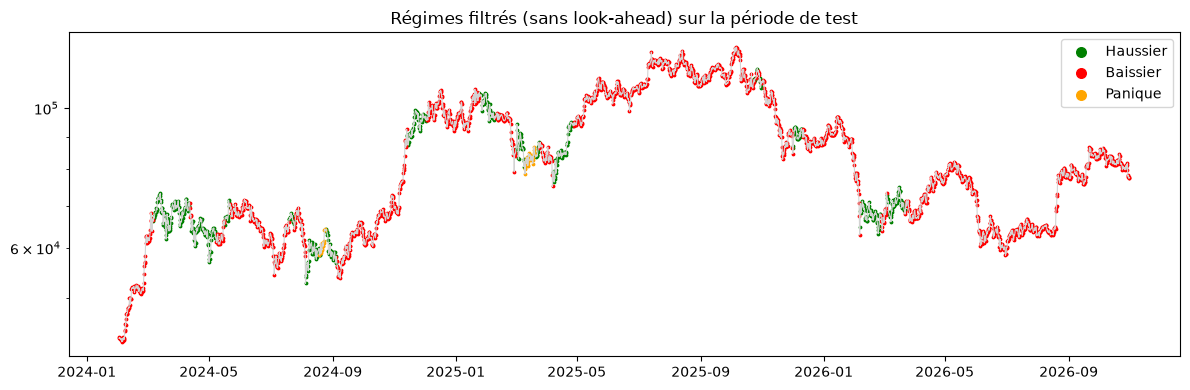

In [10]:
# Graphique : prix colorié par régime (test)
couleurs = {"Haussier": "green", "Baissier": "red", "Panique": "orange"}
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(res.index, res["Close"], color="lightgrey", lw=0.8)
for nom, col in couleurs.items():
    sel = res["regime_actuel"] == nom
    ax.scatter(res.index[sel], res["Close"][sel], s=3, color=col, label=nom)
ax.set_yscale("log"); ax.legend(markerscale=4); ax.set_title("Régimes filtrés (sans look-ahead) sur la période de test")
plt.tight_layout(); plt.savefig("../results/regimes_test.png", dpi=150); plt.show()

> **Interprétation :**
>
> Le prix du test est coloré selon le régime trouvé.
> - Le **rouge (« Baissier », en réalité calme)** couvre la majorité du graphique, **y compris de fortes hausses** (fin 2024, mi-2025) et de fortes baisses (fin 2025) : cet état ne mesure pas la direction mais le **calme**.
> - Le **vert (« Haussier », volatilité moyenne)** apparaît dans les périodes plus agitées : printemps 2024, début 2025, février-mars 2026.
> - L'**orange (« Panique »)** apparaît à deux moments précis : **début août 2024** et **mars 2025**, deux chutes brutales du marché. Le modèle les repère sans regarder le futur.
>
> Conclusion : avec des données gaussiennes, le HMM sépare bien les régimes **calme / intermédiaire / agité**, et détecte mieux les épisodes de panique. Les noms « Haussier / Baissier » sont à remplacer par des noms liés à la volatilité.